# Week 3: Visualization & Interpretation

## Project Overview

This notebook transforms the exploratory findings from
Week 2 into clear and meaningful visualizations.

The analysis uses the cleaned Food Delivery dataset
prepared during Week 1.

The objective is to visualize delivery duration patterns
and compare operational factors using five required charts.

Each visualization is followed by a short interpretation
highlighting the observed findings and relevant limitations.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Set visualization style
sns.set_theme(style="whitegrid")

# Locate project directory
project_root = Path.cwd().parent

# Load cleaned dataset
data_path = (
    project_root / "data" / "processed" / "food_delivery_cleaned.csv"
)

df = pd.read_csv(data_path, parse_dates=["Order_Date"])

# Define delivery duration column
duration_col = "Time_taken (min)"

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Delivery duration column:", duration_col)

display(df.head())

Dataset loaded successfully!
Dataset shape: (45584, 20)
Delivery duration column: Time_taken (min)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.00,4.20,30.33,78.05,30.40,78.12,2022-02-12,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.00,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.00,4.70,10.00,76.31,10.04,76.35,2022-02-13,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.00,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.00,4.70,18.56,73.92,18.65,74.01,2022-03-04,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.00,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.00,4.30,30.90,75.81,30.92,75.83,2022-02-13,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.00,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.00,4.70,26.46,80.37,26.59,80.50,2022-02-14,19:50,20:05,Fog,Jam,1,Snack,scooter,1.00,No,Metropolitian,41


## 1. Delivery Duration Distribution

This histogram shows the distribution of delivery durations
across all valid delivery records.

The chart includes reference lines for the mean and median
to help interpret the central tendency of delivery time.

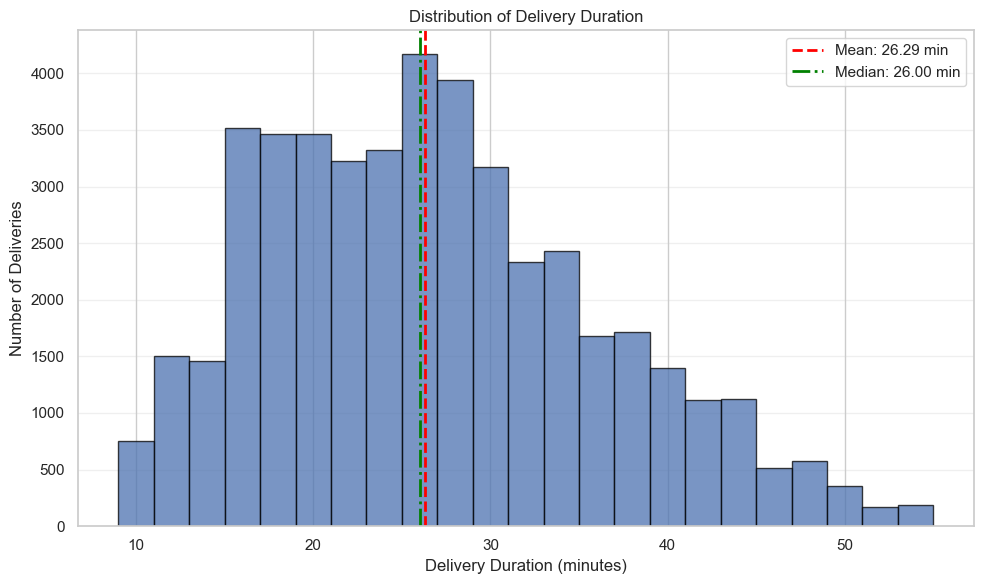

Valid records: 45584
Mean: 26.29
Median: 26.0
Minimum: 10
Maximum: 54


In [2]:
# Prepare valid delivery duration values
duration = pd.to_numeric(df[duration_col], errors="coerce").dropna()

# Calculate mean and median
mean_duration = duration.mean()
median_duration = duration.median()

# Create histogram
plt.figure(figsize=(10, 6))

plt.hist(
    duration,
    bins=np.arange(9, 56, 2),
    edgecolor="black",
    alpha=0.75
)

# Add mean and median reference lines
plt.axvline(
    mean_duration,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_duration:.2f} min"
)

plt.axvline(
    median_duration,
    color="green",
    linestyle="-.",
    linewidth=2,
    label=f"Median: {median_duration:.2f} min"
)

plt.title("Distribution of Delivery Duration")
plt.xlabel("Delivery Duration (minutes)")
plt.ylabel("Number of Deliveries")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Valid records:", len(duration))
print("Mean:", round(mean_duration, 2))
print("Median:", round(median_duration, 2))
print("Minimum:", duration.min())
print("Maximum:", duration.max())

### Chart Interpretation

The histogram shows that delivery durations are concentrated
around the central range, with a mean of 26.29 minutes and
a median of 26 minutes. The distribution is slightly
right-skewed, with delivery durations ranging from 10 to
54 minutes. A limitation is that the histogram shows the
overall distribution but does not explain differences
between operational categories.

## 2. Traffic Density Comparison

This bar chart compares median delivery duration
across different road traffic density categories.

The number of deliveries in each category is also
included to provide context for the comparison.

,Road_traffic_density,Delivery_Count,Median_Duration
1,Jam,14139,31.00
0,High,4423,27.00
3,Medium,10945,27.00
2,Low,16077,21.00


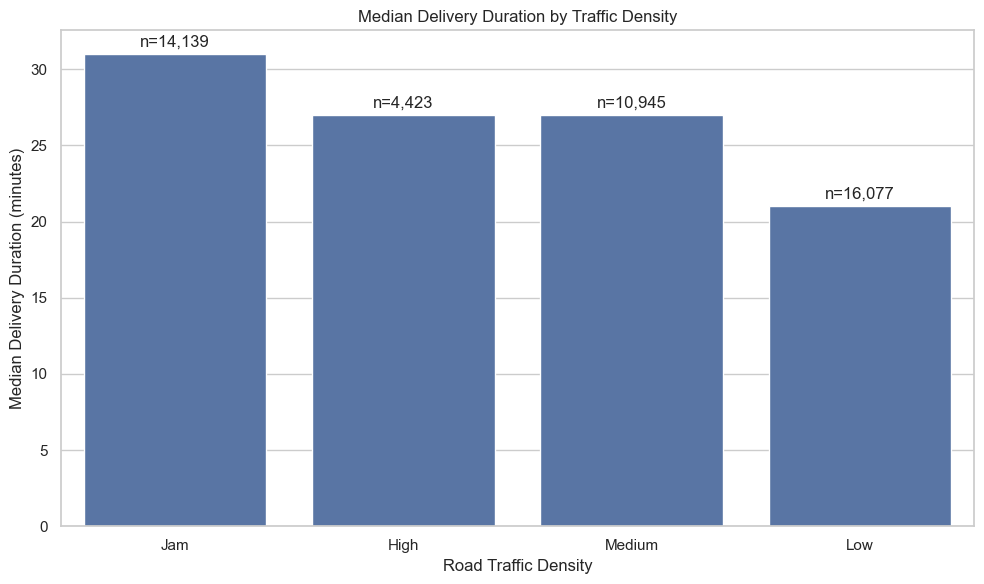

In [3]:
# Calculate median delivery duration and group size
traffic_summary = (
    df.groupby("Road_traffic_density")[duration_col]
    .agg(
        Delivery_Count="count",
        Median_Duration="median"
    )
    .reset_index()
    .sort_values("Median_Duration", ascending=False)
)

display(traffic_summary)

# Create bar chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=traffic_summary,
    x="Road_traffic_density",
    y="Median_Duration"
)

# Add group sizes above bars
for i, row in traffic_summary.iterrows():
    ax.text(
        list(traffic_summary["Road_traffic_density"]).index(
            row["Road_traffic_density"]
        ),
        row["Median_Duration"] + 0.5,
        f"n={row['Delivery_Count']:,}",
        ha="center"
    )

plt.title("Median Delivery Duration by Traffic Density")
plt.xlabel("Road Traffic Density")
plt.ylabel("Median Delivery Duration (minutes)")
plt.tight_layout()
plt.show()

### Chart Interpretation

The bar chart shows that deliveries under Jam traffic
have the highest median duration at 31 minutes, while
Low traffic has the lowest median at 21 minutes.
High and Medium traffic both have a median of 27 minutes.
These differences indicate an association between traffic
categories and delivery duration, but they do not establish
causation. Traffic records include values imputed during Week 1.

## 3. Weather Conditions Comparison

This bar chart compares average delivery duration
across different weather conditions.

The number of deliveries in each category is included
to provide context for the observed averages.

,Weather_conditions,Delivery_Count,Mean_Duration
0,Cloudy,7533,28.92
1,Fog,8269,28.74
5,Windy,7422,26.12
2,Sandstorms,7494,25.88
3,Stormy,7584,25.87
4,Sunny,7282,21.86


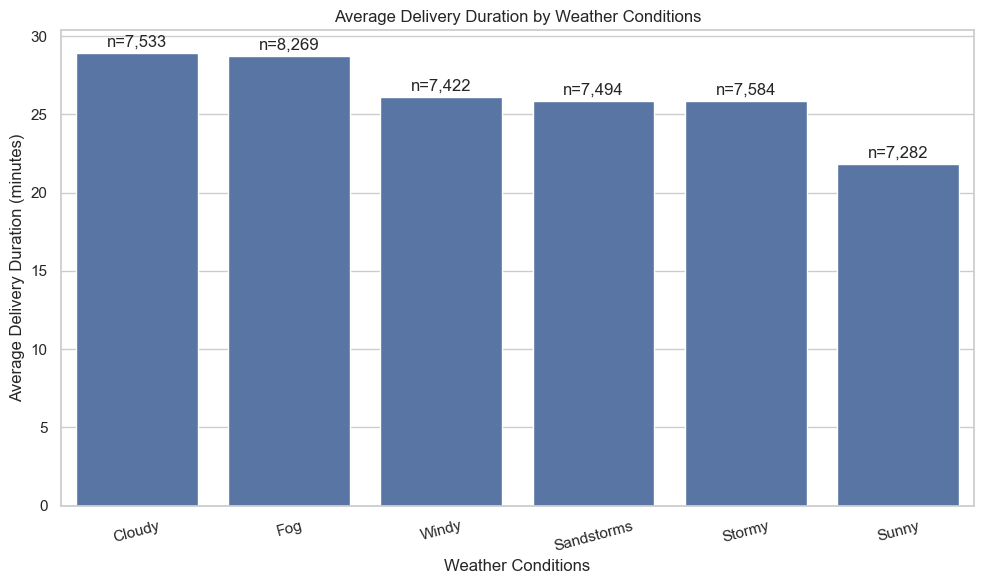

In [4]:
# Calculate average delivery duration and group size
weather_summary = (
    df.groupby("Weather_conditions")[duration_col]
    .agg(
        Delivery_Count="count",
        Mean_Duration="mean"
    )
    .reset_index()
    .sort_values("Mean_Duration", ascending=False)
)

display(weather_summary)

# Create bar chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=weather_summary,
    x="Weather_conditions",
    y="Mean_Duration"
)

# Add group sizes above bars
for i, row in weather_summary.reset_index(drop=True).iterrows():
    ax.text(
        i,
        row["Mean_Duration"] + 0.4,
        f"n={row['Delivery_Count']:,}",
        ha="center"
    )

plt.title("Average Delivery Duration by Weather Conditions")
plt.xlabel("Weather Conditions")
plt.ylabel("Average Delivery Duration (minutes)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Chart Interpretation

The bar chart shows that Cloudy conditions have the highest
average delivery duration at 28.92 minutes, followed closely
by Fog at 28.74 minutes. Sunny conditions have the lowest
average at 21.86 minutes. These results indicate differences
in delivery duration across weather categories, but do not
establish causation. Weather records include values imputed
during Week 1.


## 4. Distance vs Delivery Duration

This scatter plot examines the relationship between
straight-line delivery distance and delivery duration.

Distance is calculated using the Haversine formula.
Records with zero or negative restaurant coordinates
are excluded from this distance analysis only.

Records used: 41513
Pearson correlation: 0.321


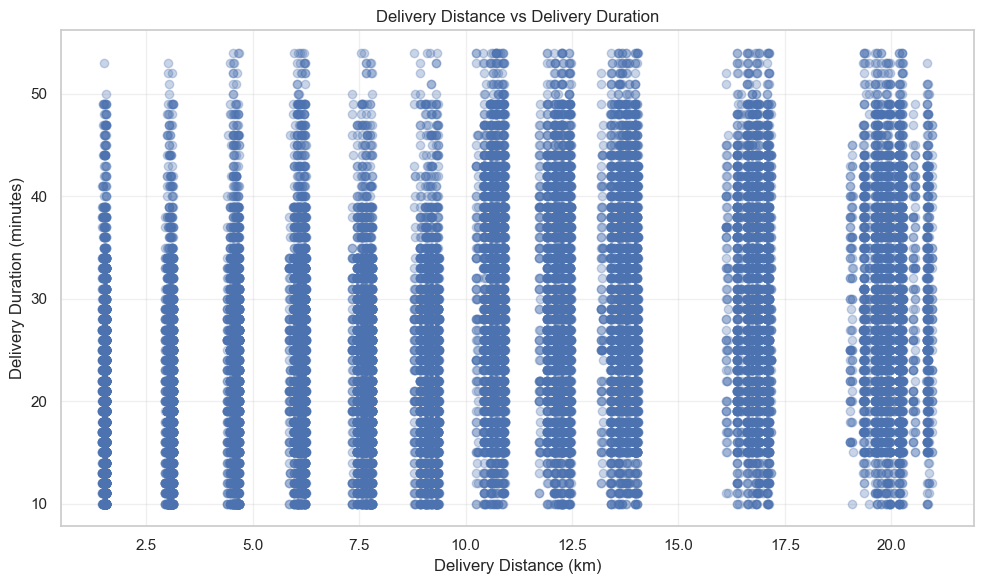

In [5]:
# Select coordinate columns
coordinate_cols = [
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

coordinates = df[coordinate_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

# Identify invalid restaurant coordinates
zero_restaurant = (
    (coordinates["Restaurant_latitude"] == 0) |
    (coordinates["Restaurant_longitude"] == 0)
)

negative_restaurant = (
    (coordinates["Restaurant_latitude"] < 0) |
    (coordinates["Restaurant_longitude"] < 0)
)

invalid_restaurant = zero_restaurant | negative_restaurant

valid_distance_mask = ~invalid_restaurant

# Prepare valid records
distance_df = df.loc[valid_distance_mask].copy()
coords_valid = coordinates.loc[valid_distance_mask]

# Convert coordinates to radians
lat1 = np.radians(coords_valid["Restaurant_latitude"].to_numpy())
lon1 = np.radians(coords_valid["Restaurant_longitude"].to_numpy())

lat2 = np.radians(
    coords_valid["Delivery_location_latitude"].to_numpy()
)
lon2 = np.radians(
    coords_valid["Delivery_location_longitude"].to_numpy()
)

# Calculate Haversine distance
dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
)

a = np.clip(a, 0, 1)

earth_radius = 6371

distance_km = (
    2 * earth_radius * np.arcsin(np.sqrt(a))
)

distance_df["Distance_km"] = distance_km

# Calculate Pearson correlation
distance_duration_corr = distance_df[
    ["Distance_km", duration_col]
].corr(method="pearson").iloc[0, 1]

print("Records used:", len(distance_df))
print("Pearson correlation:", round(distance_duration_corr, 3))

# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    distance_df["Distance_km"],
    distance_df[duration_col],
    alpha=0.3
)

plt.title("Delivery Distance vs Delivery Duration")
plt.xlabel("Delivery Distance (km)")
plt.ylabel("Delivery Duration (minutes)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Chart Interpretation

The scatter plot shows a positive, weak-to-moderate
relationship between delivery distance and delivery duration,
supported by a Pearson correlation coefficient of 0.321.
Delivery duration generally tends to increase with distance,
although considerable variation exists among records.
A limitation is that straight-line distance does not represent
actual road distance, and 4,071 records were excluded due to
invalid restaurant coordinates.

## 5. Vehicle Comparison - Box Plot

This box plot compares delivery duration distributions
across different vehicle types.

It displays the median, interquartile range, and
potential outliers for each vehicle category.

Delivery Count by Vehicle Type:


Type_of_vehicle
motorcycle          26429
scooter             15273
electric_scooter     3814
bicycle                68
Name: count, dtype: int64

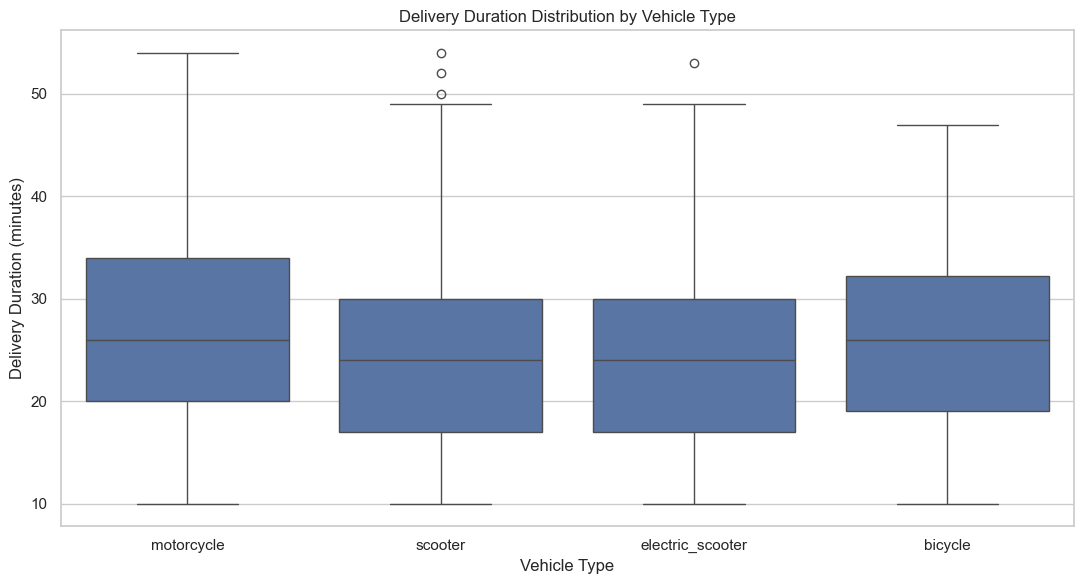

In [6]:
# Calculate group sizes
vehicle_counts = df["Type_of_vehicle"].value_counts()

print("Delivery Count by Vehicle Type:")
display(vehicle_counts)

# Create box plot
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="Type_of_vehicle",
    y=duration_col
)

plt.title("Delivery Duration Distribution by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Delivery Duration (minutes)")

plt.tight_layout()
plt.show()

### Chart Interpretation

The box plot shows differences in delivery duration
distributions across vehicle types. Motorcycle and Bicycle
have median durations of approximately 26 minutes, while
Scooter and Electric Scooter have medians of approximately
24 minutes. Several upper outliers appear for Scooter and
Electric Scooter. A key limitation is the very small Bicycle
sample size (68 records), which makes its distribution
less reliable for comparison.